# 02 · Faster R-CNN (torchvision `fasterrcnn_resnet50_fpn_v2`)
Sections: data check → anchors vs. object sizes → smoke test → baseline (step by step) → 2 tuned variants →
comparison → failure analysis → RPN proposal recall → test submission.
Shared code: `src/dataset.py` (TVDetectionDataset), `src/models_tv.py`, `src/train_tv.py`, `src/analysis.py`.
Configs: `configs/frcnn_baseline.yaml` → `frcnn_small_anchors.yaml` → `frcnn_tuned.yaml` (each inherits the previous one).

Rough T4 budget (estimates, check the it/s of the smoke test): baseline 800/1333 ≈ 25 min/epoch × 6 ≈ 2.5–3 h;
each variant at 1024/1824 ≈ 45 min/epoch × 6 ≈ 4.5–5 h. Training is resumable (checkpoint after every epoch):
re-run the same cell in a new session with the same WORK_DIR. Sections 1, 2 and 6 run on CPU.

In [1]:
# Paths: auto-detected for Kaggle and for a local clone (data in <repo>/data, outputs in <repo>/outputs).
# Override any of the three variables by hand if your layout differs.
from pathlib import Path
if Path("/kaggle/input").exists():
    DATA_ROOT = next(Path("/kaggle/input").glob("**/test_images.csv")).parent  # competition folder
    REPO_DIR  = Path("/kaggle/working/Video-Detection-HW2")                     # git clone of this repo
    WORK_DIR  = Path("/kaggle/working/outputs")
else:
    REPO_DIR  = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DATA_ROOT = REPO_DIR / "data"
    WORK_DIR  = REPO_DIR / "outputs"
assert (DATA_ROOT / "test_images.csv").exists(), f"test_images.csv not found in {DATA_ROOT}"
print("DATA_ROOT:", DATA_ROOT, "| REPO_DIR:", REPO_DIR, "| WORK_DIR:", WORK_DIR)

DATA_ROOT: /Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2/data | REPO_DIR: /Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2 | WORK_DIR: /Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2/outputs


In [2]:
# Install the pinned dependencies once per session (torch/torchvision are already on Kaggle/Colab).
# !git clone <your-repo-url> {REPO_DIR}
# !pip install -q -r {REPO_DIR}/requirements.txt
# Colab only: keep WORK_DIR on Google Drive so it survives disconnects
# from google.colab import drive; drive.mount("/content/drive")

In [3]:
# Make `src/` importable and print library versions (reproducibility)
import sys
from pathlib import Path
sys.path.insert(0, str(Path(REPO_DIR).resolve()))

from src.utils import load_config, seed_everything, print_versions, detect_env, ensure_dir
print("env:", detect_env())
print_versions()

env: local
python          3.12.6
numpy           2.4.6


torch           2.11.0


torchvision     0.26.0
ultralytics     8.4.208
faster_coco_eval 1.8.0
pycocotools     installed


ensemble_boxes  installed
sahi            0.14.0
cv2             5.0.0


wandb           0.31.0
device          CPU only


In [4]:
# Load the shared config + the three Faster R-CNN configs, fix seeds, create output folders
from src.utils import load_exp_config
cfg = load_config(Path(REPO_DIR) / "configs" / "base.yaml")
seed_everything(cfg["seed"])

DATA_ROOT, WORK_DIR = Path(DATA_ROOT), ensure_dir(WORK_DIR)
FIG_DIR = ensure_dir(Path(REPO_DIR) / "results" / "figures")
RES_DIR = Path(REPO_DIR) / "results"
GT_VAL = DATA_ROOT / "val" / "annotations_coco.json"
EXPS = {n: load_exp_config(Path(REPO_DIR) / "configs" / f"{n}.yaml")
        for n in ["frcnn_baseline", "frcnn_small_anchors", "frcnn_tuned"]}
for n, c in EXPS.items():
    m = c["model"]
    print(f"{n:20s} anchors={m['anchor_sizes']} input={m['min_size_test']}/{m['max_size']} "
          f"box_pos={m['box_positive_fraction']} loss={m['box_loss']} epochs={c['train']['epochs']}")

frcnn_baseline       anchors=[32, 64, 128, 256, 512] input=800/1333 box_pos=0.25 loss=smooth_l1 epochs=6
frcnn_small_anchors  anchors=[16, 32, 64, 128, 256] input=1024/1824 box_pos=0.25 loss=smooth_l1 epochs=6
frcnn_tuned          anchors=[16, 32, 64, 128, 256] input=1024/1824 box_pos=0.5 loss=giou epochs=6


In [5]:
# Common imports for this notebook + GPU check
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from src.utils import CLASS_NAMES, load_predictions, log_experiment, init_wandb
from src.dataset import TVDetectionDataset, read_yolo_labels, load_rgb
from src.models_tv import rpn_recall
from src.train_tv import (get_device, build_model, prepare_indices, fit, final_eval, predict_test,
                          run_experiment, summarize_params, load_trained)
from src.eval import evaluate, per_class_table
from src.viz import draw_boxes, show_grid
from src import analysis as A

DEVICE = get_device()
print("device:", DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
RUN_GPU = DEVICE.type == "cuda"  # training / GPU-only cells are skipped on CPU (set True to force)
if not RUN_GPU:
    print("No GPU: training cells are skipped; sections 1, 2 and 6 (saved predictions) run on CPU.")
pd.set_option("display.width", 160)

device: cpu 
No GPU: training cells are skipped; sections 1, 2 and 6 (saved predictions) run on CPU.


## 1. Data pipeline check (CPU)

In [6]:
# Frame indices for the baseline config: train = every 6th frame, val subset for per-epoch mAP, full val for the score
train_idx, val_epoch_idx, val_full_idx = prepare_indices(EXPS["frcnn_baseline"], DATA_ROOT)

[index] train: 56 clips, 4062 frames (step=6)
[index] val: 7 clips, 2846 frames (step=1)
[data] train 4062 | val per-epoch 714 | val final 2846


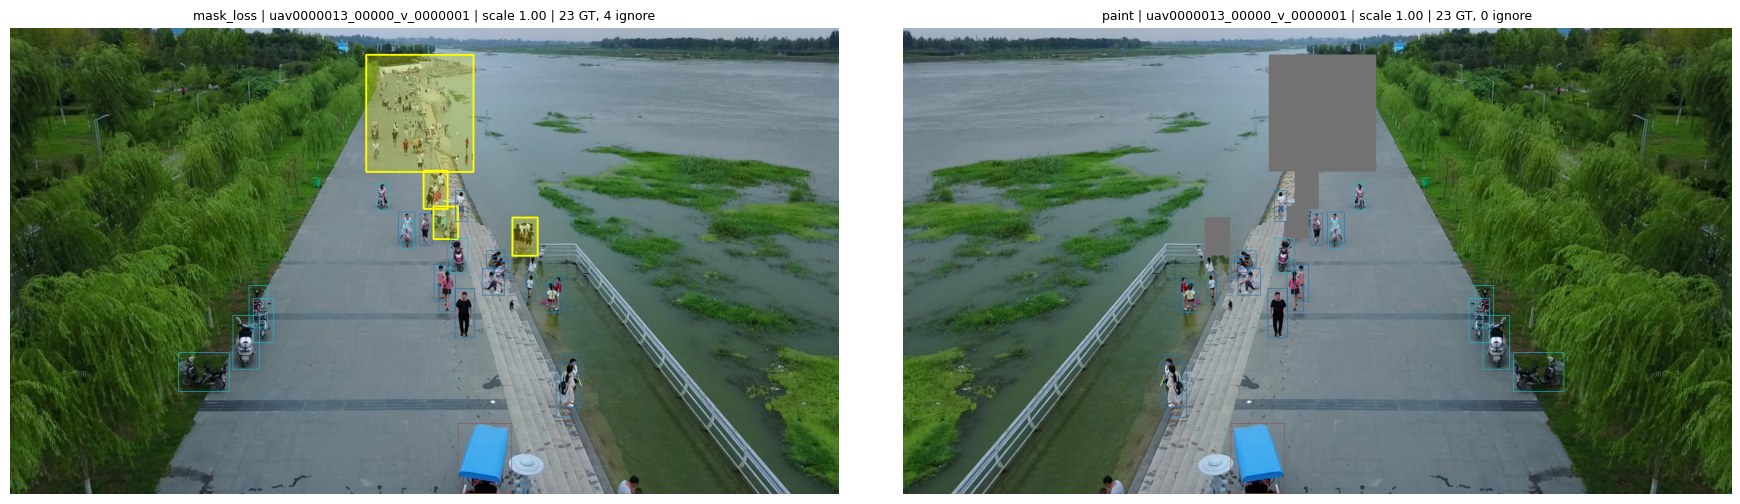

In [7]:
# One training sample per ignore mode. Left: mask_loss (flipped; ignore boxes in yellow, only used in the loss).
# Right: paint fallback (gray regions, covered GT dropped). Boxes must sit exactly on the objects.
i = int(np.argmax(train_idx["ignore_path"].astype(bool).values))  # first frame that has ignore regions
vis, titles = [], []
for mode, flip in [("mask_loss", 1.0), ("paint", 0.0)]:
    ds = TVDetectionDataset(train_idx, train=True, ignore_mode=mode, hflip=flip, max_short=1088, max_long=1824)
    img, tgt, meta = ds[i]
    b, ig = tgt["boxes"].numpy(), tgt["is_ignore"].numpy()
    bgr = img.permute(1, 2, 0).numpy()[:, :, ::-1].copy()
    vis.append(draw_boxes(bgr, b[~ig], tgt["labels"].numpy()[~ig] - 1, ignore_xyxy=b[ig]))
    titles.append(f"{mode} | {meta['key']} | scale {meta['scale']:.2f} | {(~ig).sum()} GT, {ig.sum()} ignore")
show_grid(vis, titles, ncols=2, figsize_per=(9, 5), save_path=FIG_DIR / "frcnn_dataset_check.png")

## 2. Anchors vs. object sizes at the network input (CPU)

In [8]:
# GT (w, h) rescaled by the factor the model transform applies (short side -> min_size, long side <= max_size)
from src.anchors import wh_iou

def gt_wh_at_input(index, min_size, max_size, n=800, seed=0):
    whs = []
    for r in index.sample(min(n, len(index)), random_state=seed).itertuples():
        b, _ = read_yolo_labels(r.label_path, r.width, r.height)
        s = min(min_size / min(r.width, r.height), max_size / max(r.width, r.height))
        whs.append((b[:, 2:] - b[:, :2]) * s)
    return np.concatenate(whs)

def anchor_wh(sizes, ratios):  # torchvision AnchorGenerator: h/w = ratio, area = size^2
    return np.array([[s / np.sqrt(r), s * np.sqrt(r)] for s in sizes for r in ratios])

rows = []
for n, c in EXPS.items():
    m = c["model"]
    wh = gt_wh_at_input(train_idx, m["min_size_test"], m["max_size"])
    best = wh_iou(wh, anchor_wh(m["anchor_sizes"], m["aspect_ratios"])).max(1)
    rows.append({"config": n, "input": f"{m['min_size_test']}/{m['max_size']}", "anchors": m["anchor_sizes"],
                 "median_obj_px": float(np.median(np.sqrt(wh.prod(1)))),
                 "cover_IoU>=0.5": float((best >= 0.5).mean()), "cover_IoU>=0.7": float((best >= 0.7).mean())})
anchor_cov = pd.DataFrame(rows)
anchor_cov.to_csv(RES_DIR / "frcnn_anchor_coverage.csv", index=False)
anchor_cov

,config,input,anchors,median_obj_px,cover_IoU>=0.5,cover_IoU>=0.7
0,frcnn_baseline,800/1333,"[32, 64, 128, 256, 512]",31.767958,0.746065,0.370400
1,frcnn_small_anchors,1024/1824,"[16, 32, 64, 128, 256]",43.384693,0.993816,0.506616
2,frcnn_tuned,1024/1824,"[16, 32, 64, 128, 256]",43.384693,0.993816,0.506616


In [9]:
# K-means anchor sizes from the EDA (original pixels) and the same sizes at the variant input scale
eda = json.load(open(RES_DIR / "eda_stats.json"))
km = np.array(eda["kmeans_anchors"]["9"]["wh"], dtype=float)
m = EXPS["frcnn_small_anchors"]["model"]
scales = [min(m["min_size_test"] / min(r.width, r.height), m["max_size"] / max(r.width, r.height))
          for r in train_idx.drop_duplicates("clip").itertuples()]
print("median input scale (variant):", round(float(np.median(scales)), 2))
print("k-means sizes original px:", np.sqrt(km.prod(1)).round(1))
print("k-means sizes at input   :", (np.sqrt(km.prod(1)) * np.median(scales)).round(1))

median input scale (variant): 0.96
k-means sizes original px: [       16.7        24.7          30        36.1          45        47.4        59.8        75.3       138.3]
k-means sizes at input   : [         16        23.7        28.7        34.5          43        45.3        57.1          72       132.2]


## 3. Smoke test (GPU, ~3–5 min)
Runs the whole pipeline (train 40 iterations → val → speed) on 2 frames per clip with the heaviest config
(`frcnn_tuned`: high resolution + GIoU + ignore masking). Minutes per real epoch ≈ (train frames / 2) / (it/s) / 60.
If you change code, delete `WORK_DIR/tv/frcnn_tuned_smoke` first (otherwise it resumes the old checkpoint).

In [10]:
# Smoke test: the whole pipeline on a tiny subset, plus peak GPU memory
if RUN_GPU:
    torch.cuda.reset_peak_memory_stats()
    smoke = run_experiment(EXPS["frcnn_tuned"], DATA_ROOT, WORK_DIR, smoke=True)
    print(f"peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
    del smoke; torch.cuda.empty_cache()

## 4. Baseline (torchvision defaults), step by step

In [11]:
# Build the baseline: COCO-pretrained fasterrcnn_resnet50_fpn_v2, new 8+1-class head, ignore-aware RPN / RoI heads
EXP = "frcnn_baseline"
cfgb = EXPS[EXP]
seed_everything(cfgb["seed"])
model = build_model(cfgb)
summarize_params(cfgb)

[model] fasterrcnn_resnet50_fpn_v2 | params 43.3M (trainable 43.1M) | anchors [32, 64, 128, 256, 512] x [0.5, 1.0, 2.0] | box loss smooth_l1


{'anchor_sizes': [32, 64, 128, 256, 512],
 'aspect_ratios': [0.5, 1.0, 2.0],
 'min_size_train': [800],
 'min_size_test': 800,
 'max_size': 1333,
 'rpn_post_nms_top_n_train': 2000,
 'rpn_post_nms_top_n_test': 1000,
 'rpn_batch_size_per_image': 256,
 'box_batch_size_per_image': 512,
 'box_positive_fraction': 0.25,
 'box_loss': 'smooth_l1',
 'ignore': 'mask_loss',
 'frame_step': 6,
 'epochs': 6,
 'opt': 'sgd',
 'lr': 0.01,
 'sched': 'cosine',
 'batch': 4}

In [12]:
# Train (~2.5-3 h on T4). Resumable: re-running continues from WORK_DIR/tv/frcnn_baseline/last.pt
if RUN_GPU:
    run = init_wandb(cfgb, EXP, extra_config={"params": summarize_params(cfgb)})
    state = fit(model, cfgb, train_idx, val_epoch_idx, GT_VAL, WORK_DIR / "tv" / EXP, DEVICE, run)
    display(pd.DataFrame(state["history"]))
else:
    print("skipped (no GPU)")

skipped (no GPU)


In [13]:
# Full-val evaluation with the final (last-epoch) weights + speed; predictions -> WORK_DIR/preds/frcnn_baseline_val.pkl
if RUN_GPU:
    res_b = final_eval(model, cfgb, val_full_idx, GT_VAL, WORK_DIR, EXP, DEVICE)
    display(res_b["per_class"])

In [14]:
# Log the baseline to results/experiments.csv (and W&B if enabled), then free the GPU
if RUN_GPU:
    log_experiment(EXP, cfgb["model"]["arch"], summarize_params(cfgb), res_b["metrics"], res_b["speed"],
                   train_time_min=state["train_time_min"], notes="torchvision defaults, ignore=mask_loss")
    if run is not None:
        run.log({f"final/{k}": v for k, v in res_b["metrics"].items()}); run.finish()
del model
if RUN_GPU:
    torch.cuda.empty_cache()

## 5. Tuned variants
Each step adds one group of changes, so the difference to the previous row is attributable:
baseline → **small_anchors** (anchors 16–256, input 1024/1824 + scale jitter, 2000 test proposals)
→ **tuned** (+ denser RPN/RoI sampling with 50 % positives, + GIoU box loss).
Same schedule (6 epochs, cosine) for all. Each cell is resumable.

In [15]:
# Variant 1: small anchors + higher input resolution (~4.5-5 h on T4)
if RUN_GPU:
    res_v1 = run_experiment(EXPS["frcnn_small_anchors"], DATA_ROOT, WORK_DIR,
                            notes="anchors 16-256, input 1024/1824 + jitter 896-1088")
    res_v1.pop("model"); torch.cuda.empty_cache()
    display(res_v1["per_class"])

In [16]:
# Variant 2: variant 1 + RPN/RoI sampler for dense scenes + GIoU box loss (~4.5-5 h on T4)
if RUN_GPU:
    res_v2 = run_experiment(EXPS["frcnn_tuned"], DATA_ROOT, WORK_DIR,
                            notes="v1 + rpn 512 / roi 512 @50% pos + GIoU(w=10)")
    res_v2.pop("model"); torch.cuda.empty_cache()
    display(res_v2["per_class"])

In [17]:
# Comparison from the saved val predictions (CPU-safe): overall + per-class AP for every finished run
rows = {}
for n in EXPS:
    p = WORK_DIR / "preds" / f"{n}_val.pkl"
    if p.exists():
        rows[n] = evaluate(load_predictions(p), GT_VAL, max_dets=cfg["eval"]["max_dets"], verbose=False)
cols = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR"] + [f"AP_{c}" for c in CLASS_NAMES]
cmp = pd.DataFrame(rows, index=cols).T.round(4)
if len(cmp):
    cmp.to_csv(RES_DIR / "frcnn_comparison.csv")
    display(cmp)
else:
    print("no saved predictions yet in", WORK_DIR / "preds")
exp_csv = pd.read_csv(RES_DIR / "experiments.csv")
exp_csv[exp_csv["experiment"].isin(list(EXPS))].drop_duplicates("experiment", keep="last")[
    ["experiment", "val_mAP", "AP_small", "ms_per_img", "FPS", "train_time_min"]]

no saved predictions yet in /Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2/outputs/preds


,experiment,val_mAP,AP_small,ms_per_img,FPS,train_time_min


In [18]:
# Training curves: val-subset mAP and train loss per epoch for each run (from history.csv)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n in EXPS:
    h = WORK_DIR / "tv" / n / "history.csv"
    if h.exists():
        h = pd.read_csv(h)
        ax[0].plot(h["epoch"], h["val_mAP"], marker="o", label=n)
        ax[1].plot(h["epoch"], h["loss"], marker="o", label=n)
ax[0].set(xlabel="epoch", ylabel="val mAP (every 4th frame)"); ax[1].set(xlabel="epoch", ylabel="train loss")
if ax[0].lines:
    ax[0].legend(); plt.tight_layout(); fig.savefig(FIG_DIR / "frcnn_curves.png", dpi=120); plt.show()
else:
    plt.close(fig); print("no history.csv yet")

no history.csv yet


## 6. Failure analysis (CPU, from saved predictions)
Operating point for the pictures: score ≥ 0.3, IoU ≥ 0.5, class-agnostic matching (so class confusions show up
as "wrong class" instead of FP + FN). Unmatched detections inside ignore regions are dropped (COCOeval ignores them too).
The cells are skipped until a `WORK_DIR/preds/frcnn_*_val.pkl` exists.

In [19]:
# Pick the run with the best full-val mAP and match its predictions to the GT
BEST = cmp["mAP"].idxmax() if len(cmp) else "frcnn_baseline"
gt_val = A.gt_from_coco(GT_VAL)
key2path = dict(zip(val_full_idx["key"], val_full_idx["img_path"]))
HAVE_PREDS = (WORK_DIR / "preds" / f"{BEST}_val.pkl").exists()
if HAVE_PREDS:
    preds = load_predictions(WORK_DIR / "preds" / f"{BEST}_val.pkl")
    frames, gts, fps = A.analyse_predictions(preds, gt_val, conf=0.3, iou_thr=0.5)
    print("analysing:", BEST)
    display(frames[["n_gt", "tp", "wrong_cls", "fn", "fp", "error_rate"]].describe().round(2))
else:
    print("no saved predictions -> section 6 skipped")

no saved predictions -> section 6 skipped


In [20]:
# Worst val frames (highest error rate, >= 10 objects, one per clip): green TP, orange wrong class, red missed, magenta FP
if HAVE_PREDS:
    worst = frames[frames["n_gt"] >= 10].sort_values("error_rate", ascending=False).drop_duplicates("clip").head(4)
    imgs = [A.draw_errors(load_rgb(key2path[k]), preds.get(k, np.zeros((0, 6), np.float32)), gt_val[k]) for k in worst["key"]]
    titles = [f"{r.key}: {r.n_gt} GT | missed {r.fn} | wrong cls {r.wrong_cls} | FP {r.fp}" for r in worst.itertuples()]
    show_grid(imgs, titles, ncols=2, figsize_per=(9, 5), save_path=FIG_DIR / "frcnn_worst_frames.png")
    plt.figure(figsize=(6, 0.4)); plt.legend(handles=A.error_legend(), ncol=4, loc="center"); plt.axis("off"); plt.show()
    display(worst)

In [21]:
# Confusion matrix (rows = GT, cols = prediction; last column = missed, last row = false positives)
if HAVE_PREDS:
    cm = A.confusion_matrix(gts, fps)
    fig, ax = plt.subplots(figsize=(8, 7))
    A.plot_confusion(cm, title=f"{BEST} (score>=0.3, IoU>=0.5)", ax=ax)
    fig.savefig(FIG_DIR / "frcnn_confusion.png", dpi=120, bbox_inches="tight"); plt.show()
    ci = {c: i for i, c in enumerate(CLASS_NAMES)}
    for a, b in [("van", "car"), ("car", "van"), ("truck", "van"), ("bicycle", "motor"), ("tricycle", "motor")]:
        print(f"GT {a:8s} -> predicted {b:6s}: {cm[ci[a], ci[b]] / max(cm[ci[a]].sum(), 1):.3f}")

In [22]:
# Recall per class by COCO size bucket and by VisDrone occlusion level (0 none, 1 partial, 2 heavy)
if HAVE_PREDS:
    rec_size, rec_occ = A.recall_table(gts, "bucket"), A.recall_table(gts, "occ")
    rec_size.to_csv(RES_DIR / "frcnn_recall_by_size.csv"); rec_occ.to_csv(RES_DIR / "frcnn_recall_by_occlusion.csv")
    display(rec_size.round(3)); display(rec_occ.round(3))

In [23]:
# Recall vs. object size (sqrt(area) in px) for person / car / motor: where do tiny objects get lost?
if HAVE_PREDS:
    bins = [0, 8, 12, 16, 24, 32, 48, 64, 96, 1e9]
    fig, ax = plt.subplots(figsize=(7, 4))
    for c in ["person", "car", "motor"]:
        g = gts[gts["cls"] == CLASS_NAMES.index(c)]
        r = g.groupby(pd.cut(g["size"], bins), observed=False)["matched"].mean()
        ax.plot(range(len(r)), r.values, marker="o", label=c)
    ax.set_xticks(range(len(bins) - 1), [f"{int(a)}-{int(b) if b < 1e8 else '+'}" for a, b in zip(bins[:-1], bins[1:])], rotation=30)
    ax.set(xlabel="object size sqrt(w*h) [px]", ylabel="recall (score>=0.3)", title=BEST); ax.legend(); ax.grid(alpha=.3)
    fig.savefig(FIG_DIR / "frcnn_recall_vs_size.png", dpi=120, bbox_inches="tight"); plt.show()

In [24]:
# Crops: missed tiny people (< 16 px) and vans predicted as cars (context = 1x box size on each side)
if HAVE_PREDS:
    rng = np.random.default_rng(0)
    groups = {"missed person <16px": gts[(gts["cls"] == 0) & ~gts["matched"] & (gts["size"] < 16)],
              "van -> car": gts[(gts["cls"] == 3) & (gts["pred_cls"] == 2)]}
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
    for row, (name, g) in enumerate(groups.items()):
        pick = g.iloc[rng.choice(len(g), min(8, len(g)), replace=False)] if len(g) else g
        for ax in axes[row]: ax.axis("off")
        for ax, r in zip(axes[row], pick.itertuples()):
            ax.imshow(A.crop(load_rgb(key2path[r.key]), gt_val[r.key]["boxes"][r.gt_idx])); ax.set_title(f"{name}\n{r.size:.0f}px occ={r.occ}", fontsize=7)
    plt.tight_layout(); fig.savefig(FIG_DIR / "frcnn_failure_crops.png", dpi=120); plt.show()

In [25]:
# False positives: count and score by predicted class (high-score FPs = duplicates, unlabelled objects or class confusion)
if HAVE_PREDS:
    fp_tab = fps.assign(name=fps["pred_cls"].map(lambda c: CLASS_NAMES[c])).groupby("name").agg(
        n=("score", "size"), mean_score=("score", "mean"), high_score=("score", lambda s: int((s > 0.7).sum())),
        median_size=("size", "median")).reindex(CLASS_NAMES)
    display(fp_tab.round(3))

## 7. RPN proposal recall (GPU)

In [26]:
# Recall of the top-N RPN proposals per size bucket (150 val frames): objects missed here never reach the box head
rpn_rows = []
for n in ["frcnn_baseline", "frcnn_small_anchors"]:
    if (WORK_DIR / "tv" / n / "last.pt").exists():  # ~10 s/frame on CPU -> fewer frames there
        mdl = load_trained(EXPS[n], WORK_DIR, DEVICE)
        r = rpn_recall(mdl, val_full_idx, gt_val, EXPS[n]["model"]["min_size_test"], DEVICE, n_images=150 if RUN_GPU else 20,
                       max_long=EXPS[n]["model"]["max_size"])
        rpn_rows.append(r.assign(model=n)); del mdl
if RUN_GPU:
    torch.cuda.empty_cache()
if rpn_rows:
    rpn = pd.concat(rpn_rows)
    rpn.to_csv(RES_DIR / "frcnn_rpn_recall.csv", index=False)
    display(rpn[rpn["iou"] == 0.5].pivot_table(index=["model", "top_n"], columns="bucket", values="recall").round(3))

In [27]:
# Plot: RPN recall@IoU0.5 vs number of proposals for small / all objects
if rpn_rows:
    fig, ax = plt.subplots(figsize=(6, 4))
    for (n, b), g in rpn[(rpn["iou"] == 0.5) & rpn["bucket"].isin(["small", "all"])].groupby(["model", "bucket"]):
        ax.plot(g["top_n"], g["recall"], marker="o", label=f"{n} / {b}")
    ax.set(xscale="log", xlabel="proposals per image", ylabel="recall @ IoU 0.5"); ax.legend(); ax.grid(alpha=.3)
    fig.savefig(FIG_DIR / "frcnn_rpn_recall.png", dpi=120, bbox_inches="tight"); plt.show()

## 8. Test predictions + submission (best Faster R-CNN)

In [28]:
# Predict the test set with the best run, save WORK_DIR/preds/<best>_test.pkl and a validated CSV in WORK_DIR/submissions
if RUN_GPU and (WORK_DIR / "tv" / BEST / "last.pt").exists():
    mdl = load_trained(EXPS[BEST], WORK_DIR, DEVICE)
    sub_path = predict_test(mdl, EXPS[BEST], DATA_ROOT, WORK_DIR, BEST, DEVICE)
    print("submit:", sub_path, "-> enter the public LB score by hand in results/experiments.csv (public_lb)")